# chip_10a_3x_squid — the 3X SQUID junction script, completed, on the Quantcore PDK

## 1 · What the chip is

**Source:** `components/python/chip_10a_3X_SQUID.py` (`create_squid(js, secondFinger, path)`, writes
`squid_3x_SQ_<js>.gds`; `__main__` calls `create_squid(2)`; header: "this file is used for chip_05 squids"),
Quantcore internal. Spec: `docs/designs/legacy/chip_10a_3x_squid.md`.

A SQUID junction generator. It sets up straight / bent finger pairs, 32 × 20 µm negative windows at x = ±8 µm and
HSQ boxes, but in the source every insertion except the first is commented out: the written GDS holds one non-empty
cell, `top_finger`, with two **positive** straight fingers (0.4 µm finger, 1.0 µm pad, 0.8 µm long) at (−15, ∓5) µm;
`JUNC_2` and `bottom_finger` are empty. **Completed (the design decision):** the SQUID the script's parameters
describe — two 0.2 × 0.2 µm trilayer junctions at x = ±8 µm in 32 × 20 µm windows, with HSQ — is drawn as
`TrilayerSquidHSQ` (the author's `squid_creator_HSQ` generation).

| | the rebuild keeps (source-faithful) | the Quantcore PDK changes |
|---|---|---|
| SQUID, fingers | the completed SQUID `SQ` (`TrilayerSquidHSQ`, the script's fingers, windows and spacing) and the two drawn `top_finger` fingers (`JJFingerStraight`, `negative=False`), moved 100 µm up so they do not sit inside the SQUID's left window | the SQUID valued on the PDK process: 168.75 kΩ in parallel (L_J 25.3 nH) → **flagged** (`pdk_rn`), not retuned |
| bond pads | — (probe pads belong to the test structures; no bond pads or launchers) | the pad rule (`frame.pad_edge`, 100 µm) has nothing to move (step 4) |
| cheese | — (the source has none) | the **PDK band** (3 rows of 5 µm squares, 20 µm gaps, around the 3/0 keep-outs; `cheese: "auto"`), drawn by the build and kept by the fab mask |
| placement | the bare cells at the legacy (0, 0) | the cells **centred in the die**: the fingers 100 µm above the SQUID pull the content centre 53 µm up, so everything moves by **(0, −53)** (step 7) |
| frame | — (the source writes bare cells, no die) | the PDK die frame and device ID `CHIP10A 3X` |
| FEM | — | no sim groups: nothing to excite (steps 11–12 say so) |

**Reproduced exactly** (step 15): the two drawn `top_finger` fingers on the junction layers. The completed SQUID has no legacy drawing (`JUNC_2` is empty); its construction is the `squid_creator_HSQ` cell's (golden-tested).

### Changes after design review (2026-11-03)

- **#24 completed** (review note: "complete it"): `SQ` = `TrilayerSquidHSQ` with `finger_width` = `second_finger_width` =
  0.1·js = 0.2 µm (js = 2, `secondFinger` = 0 → 0.1·js), `junction_spacing` 8 µm, 32 × 20 µm windows (the script's
  `width`/`height`), HSQ boxes on 50/0 with the 51–53/0 gradient — the commented-out `JJ_finger Top` / `JJ_finger
  Bottom` / HSQ insertions of `create_squid`. The positive `top_finger` pair stays as drawn, 100 µm above the SQUID.
- **#1 junction values — PDK trilayer rule** (Nb, Δ = 1.4 meV, I_c·R_n = πΔ/2e = 2.20 mV; PDK process R_n·A
  13.5 kΩ·µm², assumed by the PDK): each 0.04 µm² junction R_n = 337.5 kΩ, the SQUID 168.75 kΩ in parallel
  (L_J 25.3 nH at zero flux) — far above the 40–50 kΩ qubit window: a 0.2 µm "3X" junction is a small
  test junction on this process.

### PDK conformance pass (notebooks-legacy, 2026-11-18)

- **Pads:** none. The probe pads belong to the test structures and are not bond pads or launchers, so the pad rule
  (`frame.pad_edge`, 100 µm) has nothing to move; `C.pads_md(d)` confirms it (step 7).
- **Centring:** `L.center_circuit` (each axis only if > 50 µm off): shift (0, −53): the fingers 100 µm above the SQUID pull the content centre 53 µm up.
- **Cheese:** the source has none, so the PDK band applies (`cheese: "auto"`), drawn by the build and kept by the
  fab mask.
- **Junctions:** the legacy fingers, valued on the PDK process; `pdk_rn` flags a junction outside 40–50 kΩ (only
  cells that carry lumped junction values are checked), never retuned.
- **No FEM groups** (nothing to excite): steps 11 and 12 say so.
- Educative layout: one step per stage; the steps that do not apply to a test chip (pads, routes, FEM) say so.

## 2 · Setup and the Quantcore PDK

The helpers keep the cells short: `_common` (`C`) holds the netlist / LOM / FEM-export / snapshot helpers and
the PDK checks shared by every design notebook; `_legacy` (`L`) maps the legacy PCell parameters onto the
Quantcore cells, draws the legacy reference with the author's own legacy code (read-only), and holds the step
helpers of these notebooks (`_legacy_b`, `LB`, adds the legacy cells of the later chips). `LIVE` decides whether the design is pushed to a running KLayout (`QCC_LIVE=0`
for batch runs: nothing reaches KLayout).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                       # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
sys.path.insert(0, str(ROOT / "examples" / "designs" / "legacy"))
LIVE = os.environ.get("QCC_LIVE", "1") == "1"       # live KLayout by default; QCC_LIVE=0 for batch runs
import _common as C                                  # netlist / LOM / FEM-export / snapshot / PDK-check helpers
import _legacy as L                                  # legacy frame shift, parameter mapping, legacy reference, steps
import _legacy_b as LB                               # Connector Pad 2, holes, labels, xjc scripts, junction XOR

from IPython.display import Image, Markdown, display
from quantcore_circuits.designer import Designer
from quantcore_circuits.pdk import get_pdk

ID, OUT = "chip_10a_3x_squid", Path("examples/designs/legacy")

The PDK facts this rebuild uses, read from `get_pdk()` (nothing below is typed in by hand). The rules that
change a legacy chip are the **pad rule** (step 4), the **junction rule** (step 5), the **3/0 keep-out**
and the **cheese rule** (drawn by the build, step 14) and the centring of the content (step 7).

In [3]:
CHEESE_NOTE = 'PDK band (auto) — the source has no cheese of its own'
display(Markdown(L.pdk_facts_md(CHEESE_NOTE)))

| PDK item | value |
|---|---|
| PDK | `quantcore_nb_sapphire_v1` (version 3) |
| stack | sapphire, 650 µm, ε_r 10.25; Nb film (sheet metal in the FEM exports, 0.2 µm for the analytic CPW formulas) |
| CPW default | 10 µm centre, 6 µm gap, bends r = 100 µm |
| die frame | L-shaped dicing markers 25 µm wide (250 µm legs, 1000/0), 3 × 3 alignment grids (1001/0) in 500 µm corner squares, design area 100 µm inside the die edge, device ID optional (bottom centre, or beside the pads) |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (the design-area margin) from the die edge, whatever the original did (`edge="auto"`, DRC design warning `pad_edge`) |
| junction rule | Nb/AlOx/Nb trilayer, Δ = 1.4 meV (I_c·R_n = πΔ/2e), R_n 40–50 kΩ (nominal 45), qubits 4–8 GHz; R_n·A 13500 Ω·µm² and C_J 50 fF/µm² assumed; cells `Quantcore Junction` / `Quantcore Squid` (DRC design warnings `pdk_rn`, `pdk_fq`: flagged, never retuned) |
| 3/0 keep-out | second-metal etch: routes + 10 µm, components' etch bbox + 24 µm, other 1/0 shapes + 9 µm (filled) |
| cheese rule | 3 rows of 5 µm squares, 20 µm gaps, in a band around the 3/0 keep-outs; **the original design's own cheese wins** (chip `cheese`: `"auto"` / `"pdk"` / `"original"`). This chip: PDK band (auto) — the source has no cheese of its own |

### The source's numbers

`create_squid(2)`'s numbers in its own frame (µm): js, the finger width, the `padt_params` of the positive straight
fingers, and the 100 µm `TOP_SHIFT` of the `top_finger` pair (#24).

In [4]:
# chip_10a_3X_SQUID.py create_squid(2), legacy frame (µm)
JS = 2                                               # __main__: create_squid(2)
W_FINGER = 0.1 * JS                                  # finger_width = JS_default * js (bias 0); secondFinger 0 → same
FINGER = dict(negative=False, window_width=0.5, window_height=0.5, finger_length=0.8, x=8, y=0,
              finger_width=0.4, pad_width=1.0)       # padt_params of the positive straight fingers
TOP_SHIFT = 100.0                                    # top_finger moved up, clear of the SQUID's left window (#24)

## 3 · The die and the frame

`Designer(ID, box=...)` starts an empty 7.5 × 7.5 mm die (the PDK standard die). The PDK frame is drawn on every
build: four L-shaped dicing markers (1000/0), the 3 × 3 alignment grids (1001/0), the chip boundary (100/0) and the
device ID `CHIP10A 3X` (`name_chip`; optional: the frame places it where it is free). The chip parameter
`cheese` is left at `"auto"`: the source has no cheese, so the build draws the PDK band (visible from step 5 on).

(0.0, 0.0, 7500.0, 7500.0) quantcore_nb_sapphire_v1


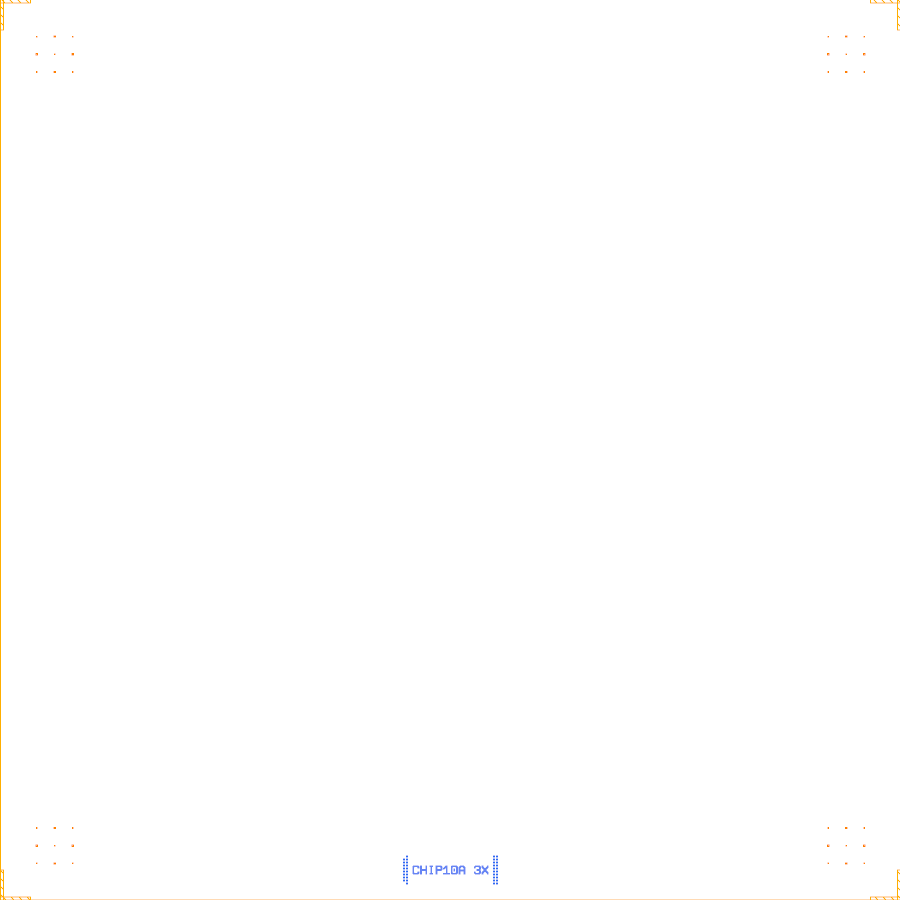

WindowsPath('build/legacy_steps/chip_10a_3x_squid_1_frame.png')

In [5]:
d = Designer(ID, box=(0, 0, L.W, L.H), chip={"name_chip": "CHIP10A 3X"}, live=LIVE)   # cheese "auto"
print(d.design.chip.box, d.design.pdk)
L.step_snapshot(d, "1_frame")

## 4 · Pads (PDK pad rule): does not apply

The PDK pad rule puts every bond pad / launcher with its outer etch `frame.pad_edge` = 100 µm from the die edge
(`edge="auto"`). This chip has none: its probe pads are part of the test structures (placed in step 5, at the
source's positions, all well inside the design area). Step 7 lists the chip's bond pads with `C.pads_md(d)`: none.

## 5 · Components: the test structures

The completed SQUID `SQ` (`TrilayerSquidHSQ`) at the legacy (0, 0) = die centre, with the PDK process values of
its two drawn junctions in parallel (`L.jj(..., n=2)`); the two `JJ_finger Top` instances of `top_finger` as
`JJFingerStraight` with the legacy parameters (`padt_params`; `conn_height` is not a parameter of that PCell and is
dropped), at `Trans(0, True, −15, −5)` and `Trans(2, True, −15, +5)`, shifted by `TOP_SHIFT` = 100 µm in y.

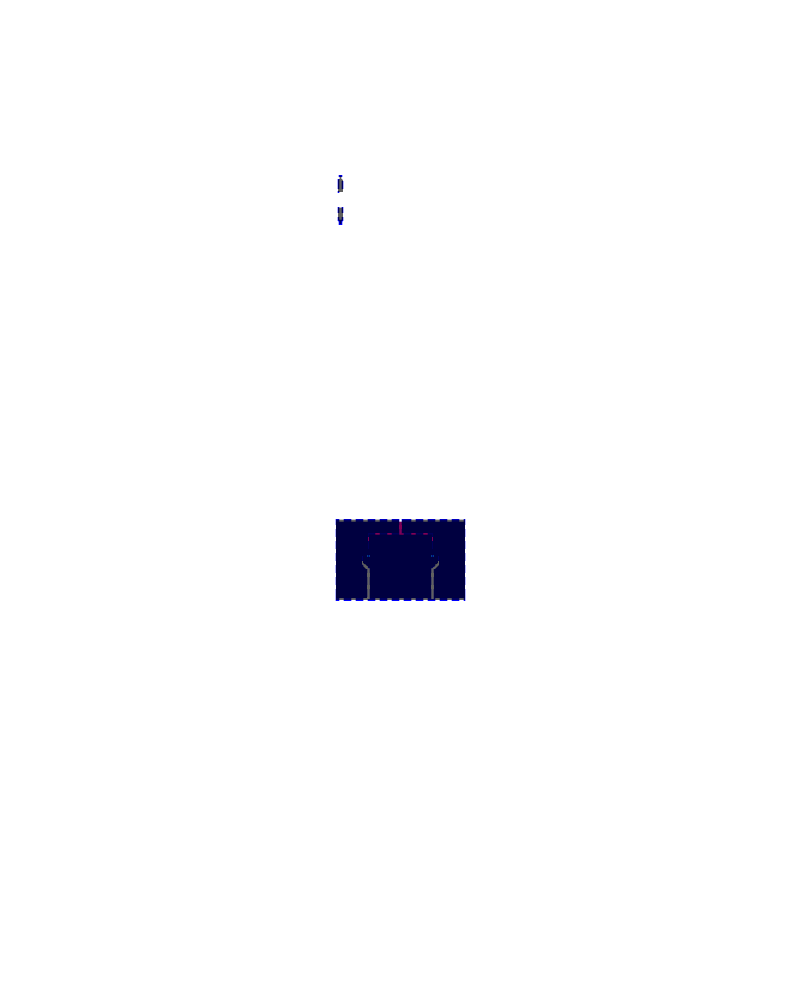

WindowsPath('build/legacy_steps/chip_10a_3x_squid_2_squid.png')

In [6]:
with d.batch():
    d.add("SQ", "TrilayerSquidHSQ", **L.place(0, 0), finger_width=W_FINGER, second_finger_width=W_FINGER,
          junction_spacing=8.0, window_width=32.0, window_height=20.0,
          junction=L.jj(W_FINGER, W_FINGER, n=2))        # #24: the SQUID the script describes; PDK process values (#1)
    d.add("FA", "JJFingerStraight", **L.place(-15, -5 + TOP_SHIFT, 0, True), **FINGER)
    d.add("FB", "JJFingerStraight", **L.place(-15, +5 + TOP_SHIFT, 2, True), **FINGER)
L.step_snapshot(d, "2_squid", box=(3650, 3650, 3850, 3900), size=(800, 1000), width=320)

## 6 · Routes: does not apply

No routes: the test structures are probed directly (needles or wire bonds on their own pads), nothing is wired on
chip.

## 7 · Cheese, pads check and centring

**Cheese.** The source has no cheese, so the build draws the **PDK band** (`cheese: "auto"`): 3 rows of 5 µm squares
with 20 µm gaps around the 3/0 keep-outs, at least 4 µm from 3/0, never over empty ground (visible in the snapshots
as the dotted rings around each structure).

**Centring (PDK placement rule).** `L.center_circuit` measures the circuit (instances, free text labels left out) and
shifts the design so it sits in the middle of the die, each axis only if it is more than 50 µm off. Then the design
is saved, and `C.pads_md(d)` checks the pad rule (no bond pads).

centring shift (µm): (0.0, -53.0) | <Designer chip_10a_3x_squid: 3 instances, 0 routes, live=False> → examples\designs\legacy\chip_10a_3x_squid.json


| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| – | no bond pads or launchers | – | – | – |

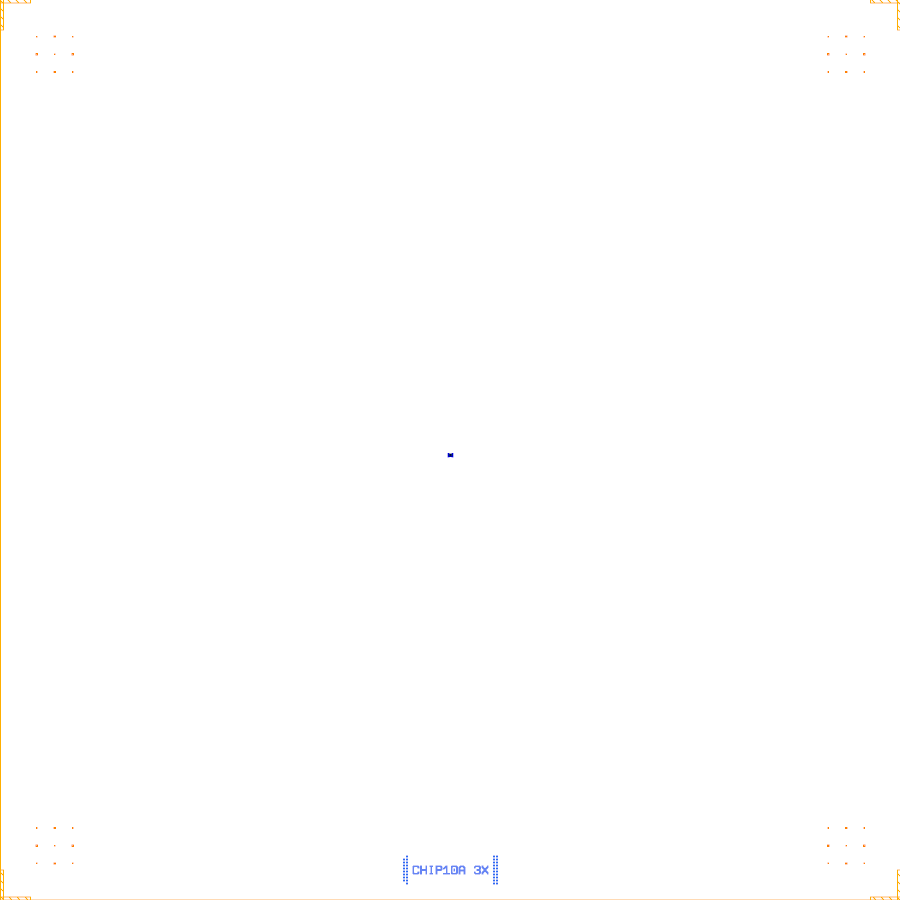

WindowsPath('build/legacy_steps/chip_10a_3x_squid_3_centred.png')

In [7]:
SHIFT = L.center_circuit(d)
DESIGN = d.save(OUT / f"{ID}.json")
print("centring shift (µm):", SHIFT, "|", d, "→", DESIGN)
display(Markdown(C.pads_md(d)))
L.step_snapshot(d, "3_centred")

## 8 · DRC

`d.drc()` builds the chip and checks it: **errors** (overlapping etch of unrelated cells, ports not landing,
parts outside the chip, a route looping over itself or running over a component) must be fixed; **warnings** are
reported for a person to judge (a dangling open end, two cells' bounding boxes touching); **PDK design warnings**
(`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`) flag values outside the PDK margins — they are never retuned for, only
listed. `C.pdk_report(d)` summarises the PDK checks: cheese source, content centring (free text labels left out),
junction types and the design warnings.

Expected (this run): zero errors; `dangling_port` `SQ.common` (a bare test SQUID: nothing attached); `overlap` FA / FB
(the two finger cells' bounding boxes, with their protection margins, touch; the fingers themselves are 4 µm apart,
y = −6 … −2 and 2 … 6 µm legacy, as in the legacy cell: XOR 0 below); **1 PDK design warning** `pdk_rn`: the SQUID's
168.8 kΩ in parallel (L_J 25.25 nH) is outside 40–50 kΩ — flagged, not retuned (#24 keeps the script's 0.2 µm
fingers). `pdk_report`: cheese "PDK band", content centre (+0, +0) µm after the (0, −53) shift, junction types
`Trilayer Squid HSQ` × 1. The device ID `CHIP10A 3X` sits at the bottom edge centre.

In [8]:
drc = d.drc()
print(drc)
display(Markdown(C.pdk_report(d)))

warning dangling_port SQ.common is not connected (no route or snap)
design  pdk_rn        SQ: junction R_n 168.8 kΩ is outside the PDK window 40–50 kΩ (L_J 25.2541 nH)
warning overlap       FA and FB overlap


| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | Trilayer Squid HSQ × 1 |
| PDK design warnings | 1 (pdk_rn × 1) |
| pdk_rn | SQ: junction R_n 168.8 kΩ is outside the PDK window 40–50 kΩ (L_J 25.2541 nH) |

## 9 · Netlist and LOM

The SQUID `SQ` is one `SQUID` branch (L_J 25.3 nH, C_J 4 fF: the design's PDK-process values) between its island node
`SQ.j` and ground; its `common` port is a bare node (nothing attached: a test structure, one unconnected port). The
fingers are bare shapes without ports.

In [9]:
lb = d.lom()
C.show_netlist(lb)
print(C.lom_summary(lb))

**2 nodes · 1 branches · 0 controls · 1 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `SQ.j` | `SQ.island` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `J_SQ` | SQUID | `SQ.j` – `gnd` | Lj 25.3 nH, Cj 4 fF |

**Unconnected ports:** `SQ.common`

{'nodes': 1, 'branches': 1, 'controls': 0, 'unconnected': 1}


## 10 · LOM simulation: does not apply — the junction table instead

A bare SQUID cell has no circuit to simulate (its `common` port is a bare node); the table gives its two junctions
(straight 0.1·js = 0.2 µm × bent 0.2 µm at x = ±8 µm) on the PDK junction rule, one and both in parallel.

In [10]:
display(Markdown(L.junction_table([
    ("SQ: one junction", W_FINGER, W_FINGER, 1),
    ("SQ: SQUID, 2 in parallel (zero flux)", W_FINGER, W_FINGER, 2),
])))

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| SQ: one junction | 0.2 × 0.2 | 1 | 0.0400 | 337.50 | 6.5 | 50.508 | 2.00 |
| SQ: SQUID, 2 in parallel (zero flux) | 0.2 × 0.2 | 2 | 0.0800 | 168.75 | 13.0 | 25.254 | 4.00 |

**Reading the numbers** (this run): one 0.2 × 0.2 µm junction is 337.5 kΩ (L_J 50.5 nH, C_J 2 fF); the SQUID, two in
parallel at zero flux, 168.75 kΩ (25.3 nH, 4 fF): a small test SQUID on this process, 3.75 × the PDK's 45 kΩ.

## 11 · FEM: send the job — does not apply

A FEM job needs a sim group: a qubit / resonator cut-out with a port to excite. This chip has none (probe
structures only), so `C.export_sims(DESIGN)` exports nothing and `L.fem_send` says so. The cell stays so the
notebook has the same shape as the others (and `RUN_FEM` would have nothing to solve).

In [11]:
RUN_FEM = False                       # nothing to solve: the chip has no sim groups
jobs = C.export_sims(DESIGN)
display(Markdown(C.jobs_md(jobs) if jobs else "*no sim groups — nothing to export*"))
display(Markdown(L.fem_send(jobs, run=RUN_FEM)))

*no sim groups — nothing to export*

AEDT on this machine: `C:\Program Files\AnsysEM\v241\Win64\ansysedt.exe` (v241)

No FEM jobs: this chip has no sim groups (nothing to excite).

## 12 · Bring the results back — does not apply

No jobs, so no results to bring back (`L.fem_bring_back` says "No FEM jobs."). On a test chip the "results" are the
probe-station R_n values, compared with the junction table of step 10.

In [12]:
display(Markdown(L.fem_bring_back(d, DESIGN, jobs, groups=None)))

No FEM jobs.

## 13 · Iterate: change one property and rebuild

The 3X SQUID's 168.75 kΩ is far outside the PDK window (`pdk_rn`). A copy draws both junctions square at 0.39 µm
(0.15 µm² each: 90 kΩ per junction, 45 kΩ in parallel, the PDK nominal SQUID), with the matching lumped values,
rebuilds it and runs the DRC again: the `pdk_rn` warning goes away. The copy is not saved; the chip keeps the
script's 0.2 µm fingers (#24).

In [13]:
d2 = Designer.load(DESIGN, live=False, verbose=False)      # a copy of the saved design
W_NEW = 0.39                                                # 0.39² ≈ 0.15 µm² → 90 kΩ per junction, 45 kΩ in parallel
d2["SQ"].set(finger_width=W_NEW, second_finger_width=W_NEW, junction=L.jj(W_NEW, W_NEW, n=2))
display(Markdown(L.junction_table([("SQ as drawn, 2 in parallel", W_FINGER, W_FINGER, 2),
                                   (f"SQ, {W_NEW} µm fingers, 2 in parallel", W_NEW, W_NEW, 2)])))
pdk_warnings = lambda rep: [i.rule for i in rep.issues if i.rule.startswith("pdk_")]
print("PDK design warnings:", pdk_warnings(drc), "→", pdk_warnings(d2.drc()))

PDK junction rule: Nb trilayer, Δ = 1.4 meV → I_c·R_n = πΔ/2e = 2.199 mV; PDK process R_n·A = 13500 Ω·µm² (J_c = 0.163 µA/µm²; nominal 0.5 × 0.6 µm → 45 kΩ, L_J 6.73 nH), C_J = 50 fF/µm² (R_n·A and C_J assumed by the PDK).

Drawn junctions (legacy fingers) on the PDK process:

| junction | fingers (µm) | n | area (µm²) | R_n (kΩ) | I_c (nA) | L_J (nH) | C_J (fF) |
|---|---|---|---|---|---|---|---|
| SQ as drawn, 2 in parallel | 0.2 × 0.2 | 2 | 0.0800 | 168.75 | 13.0 | 25.254 | 4.00 |
| SQ, 0.39 µm fingers, 2 in parallel | 0.39 × 0.39 | 2 | 0.3042 | 44.38 | 49.6 | 6.641 | 15.21 |

PDK design warnings: ['pdk_rn'] → []


**Result** (this run): with 0.39 µm square fingers the SQUID reads 44.4 kΩ in parallel (L_J 25.25 → 6.64 nH, C_J 4.0 →
15.2 fF), inside the window: the copy's DRC has no `pdk_rn` any more (`['pdk_rn']` → `[]`).

## 14 · Build and export

The design is saved as JSON (`DESIGN`, step 7): it is the source of truth — the layout, the netlist, the
FEM jobs and the mask are all made from it. The **fab mask** (`export_fab`) keeps only the PDK fab layers
(1/0 etch, 2/0 + 4/0 junction fingers, 3/0 second-metal keep-out, 50–53/0 spacer, 100/0 boundary, 1000/0 +
1001/0 markers), rounds the corners (radius ∝ each polygon's shortest dimension) and keeps the build's
cheese; every cheese hole of 1/0 is also on 3/0. **Simulation exports** never carry cheese; they drop airbridges
unless asked (`build_simulation(..., airbridges=True)`); the legacy chips have none.

Here: `cheese=True` (the default): the build already carries the PDK band (the source has no cheese), so the mask
keeps it (`cheese_source` "build"), on 1/0 and on 3/0.

The same from a shell:

```
qcc build examples/designs/legacy/chip_10a_3x_squid.json                    # layout → build/chip_10a_3x_squid.oas
qcc mask  examples/designs/legacy/chip_10a_3x_squid.json          # fab mask with the PDK rules
```

In [14]:
display(Markdown(L.fab_md(d)))

Fab mask: `build/chip_10a_3x_squid_fab.oas` · cheese source **build** (38 PDK-band holes) · corner rounding on

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 48 |
| 2/0 | JJ_STRAIGHT | 3 |
| 3/0 | M3 | 42 |
| 4/0 | JJ_BENT | 1 |
| 50/0 | HSQ | 4 |
| 51/0 | SPACER_1 | 4 |
| 52/0 | SPACER_2 | 4 |
| 53/0 | SPACER_3 | 4 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

## 15 · Snapshots and comparison with the legacy geometry

Full die (the cells are a dot at the centre, below the device ID); the completed SQUID with both windows and junctions; the 12 µm `top_finger` cell with both fingers (100 µm above).

Then `create_squid(2)` run read-only through `tests/legacy_ref` (the author's `JJ_finger` PCells), its `top_finger`
cell placed at the legacy (0, `TOP_SHIFT`) and moved by the centring shift, and the XOR per junction layer against
the rebuild in that cell's box (legacy 2/0 → `1t1_SIS_junction`; slivers ≤ 2 nm ignored). `JUNC_2` and
`bottom_finger` are empty in the legacy output, so the completed SQUID has no legacy drawing to compare with.

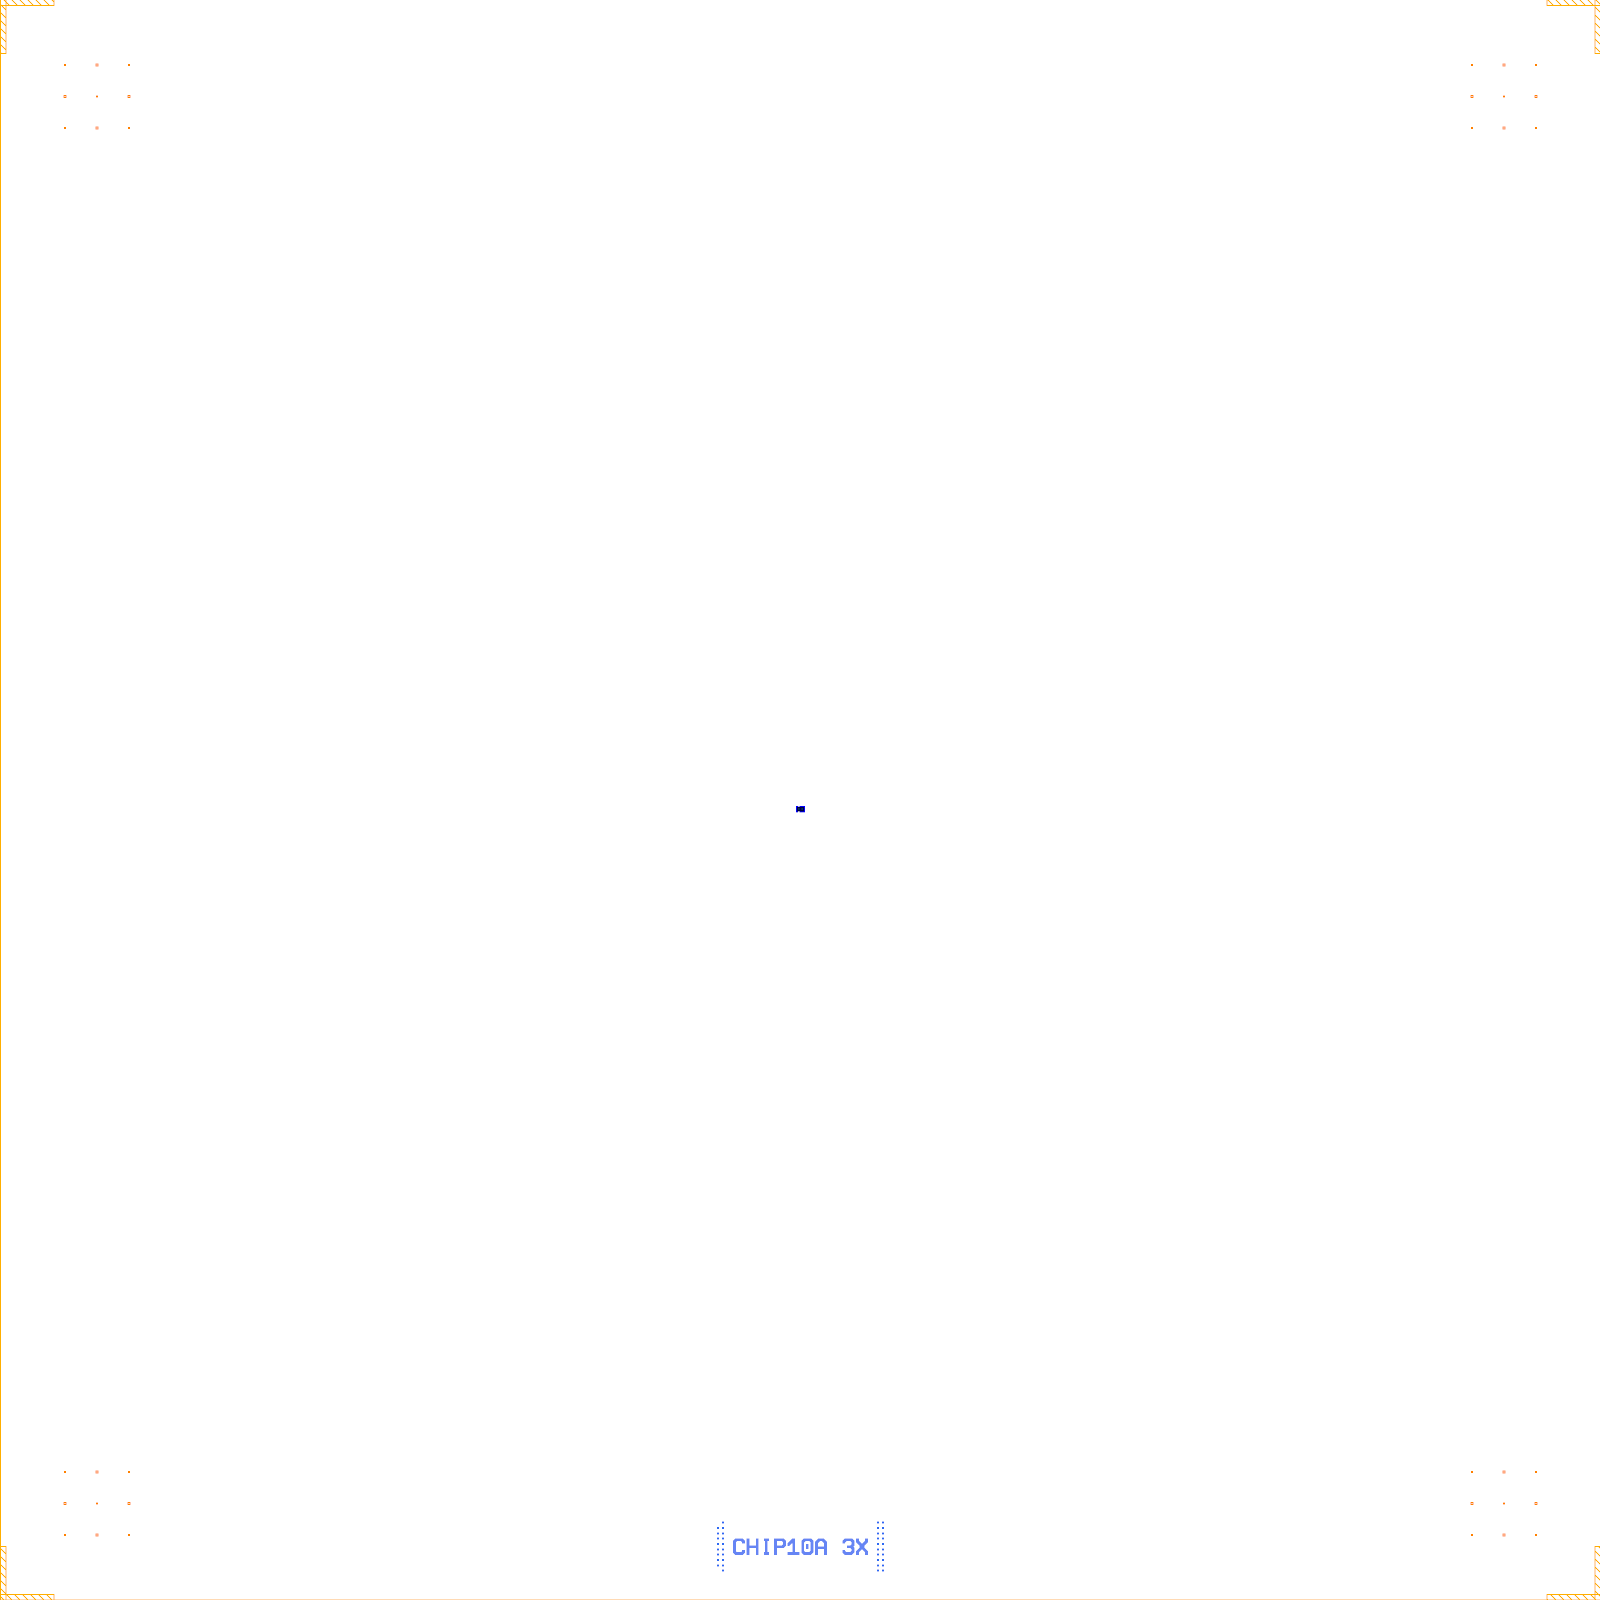

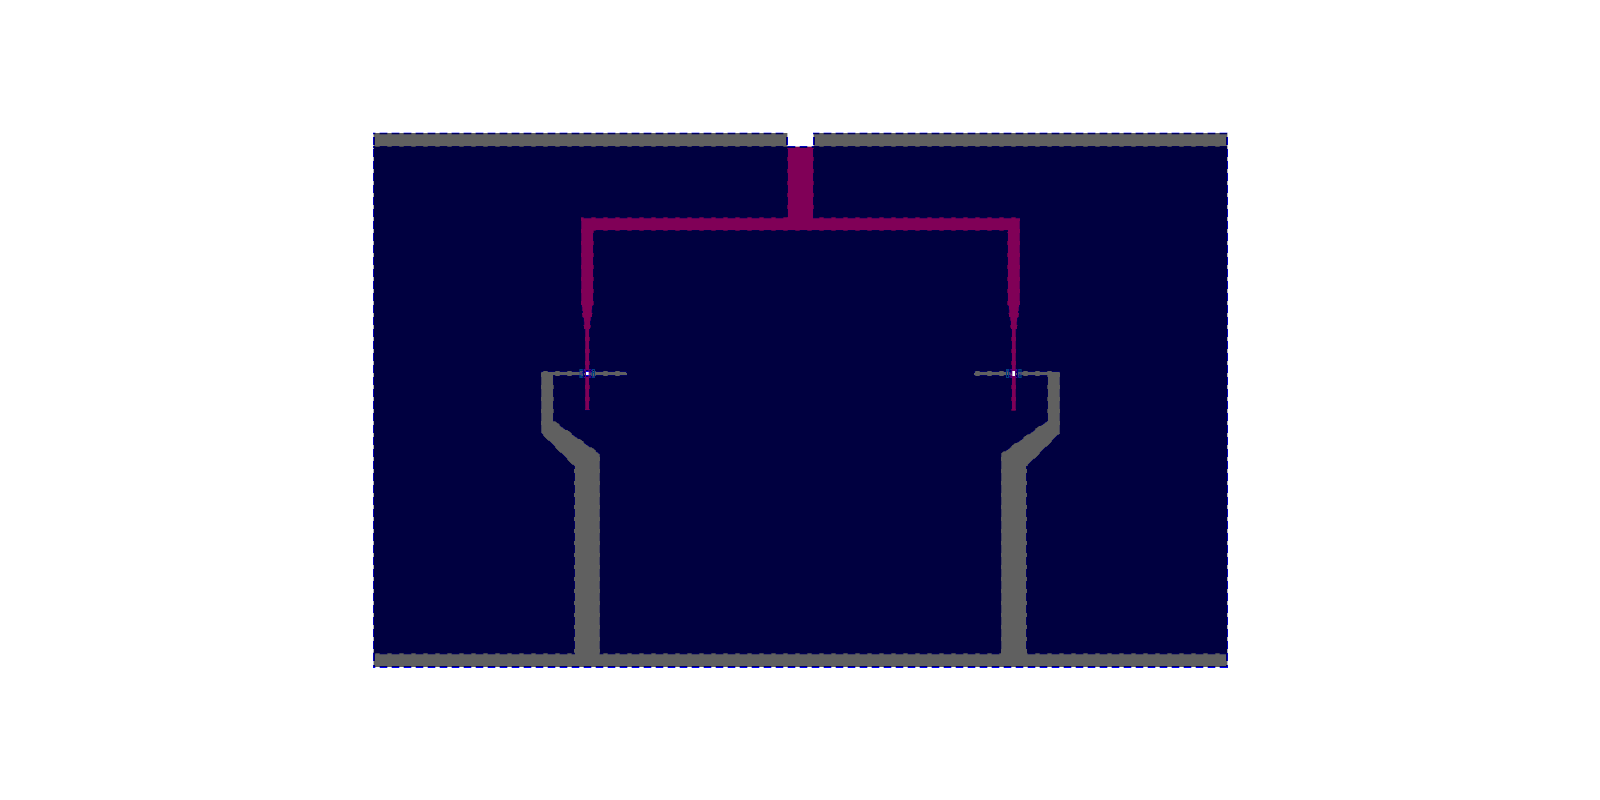

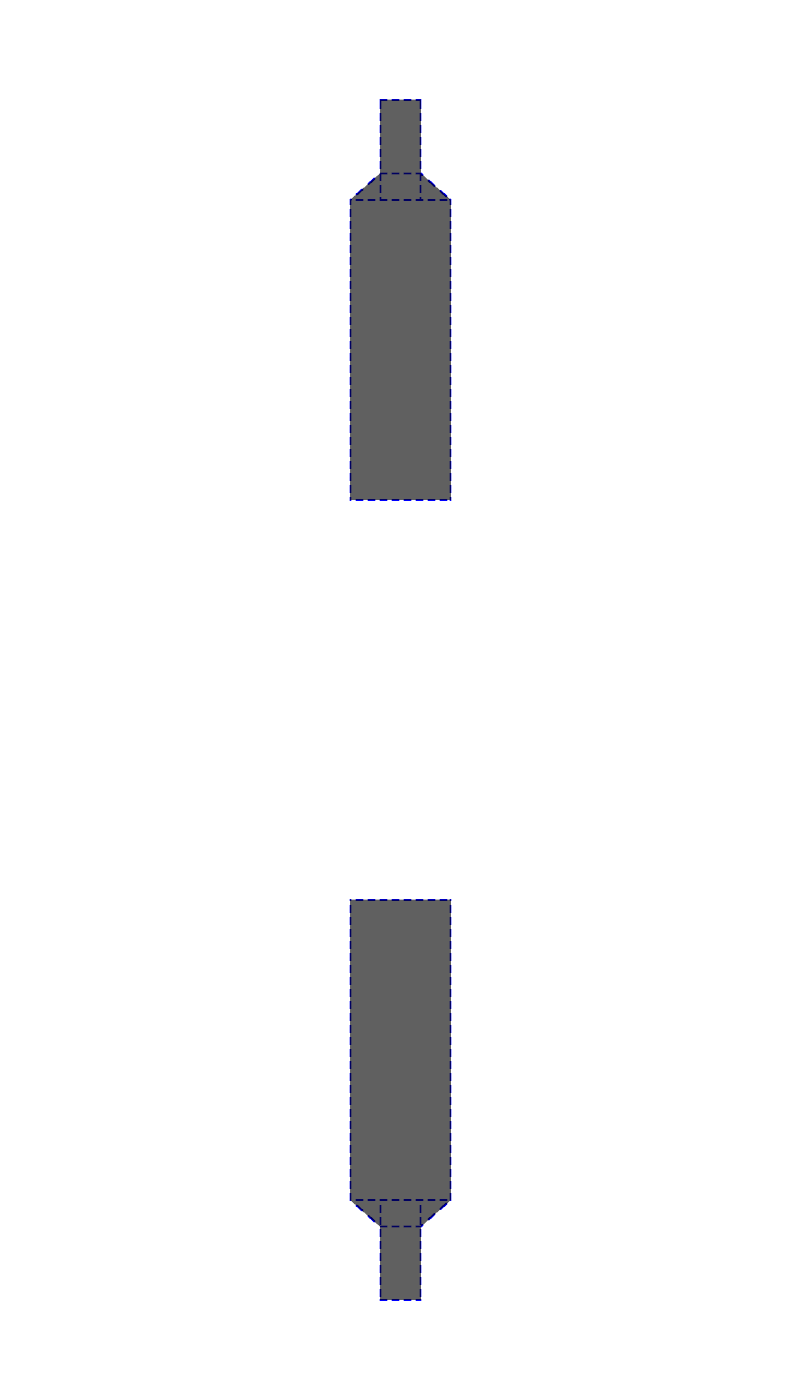

WindowsPath('examples/designs/legacy/chip_10a_3x_squid_fingers.png')

In [15]:
(xs, ys) = L.origin(d, "SQ")
(x0, y0) = (xs - 15, ys + TOP_SHIFT)                 # the top_finger pair
C.show_snapshot(d, OUT / f"{ID}.png", box=(0, 0, L.W, L.H))   # die box (the instance-name layer reaches past it)
C.show_snapshot(d, OUT / f"{ID}_squid.png", box=(xs - 30, ys - 5, xs + 30, ys + 25), size=(1600, 800), width=500)
C.show_snapshot(d, OUT / f"{ID}_fingers.png", box=(x0 - 4, y0 - 7, x0 + 4, y0 + 7), size=(800, 1400), width=300)

{'JUNC_2': '()', 'bottom_finger': '()', 'top_finger': '(-15.5,-6;-14.5,6)'}


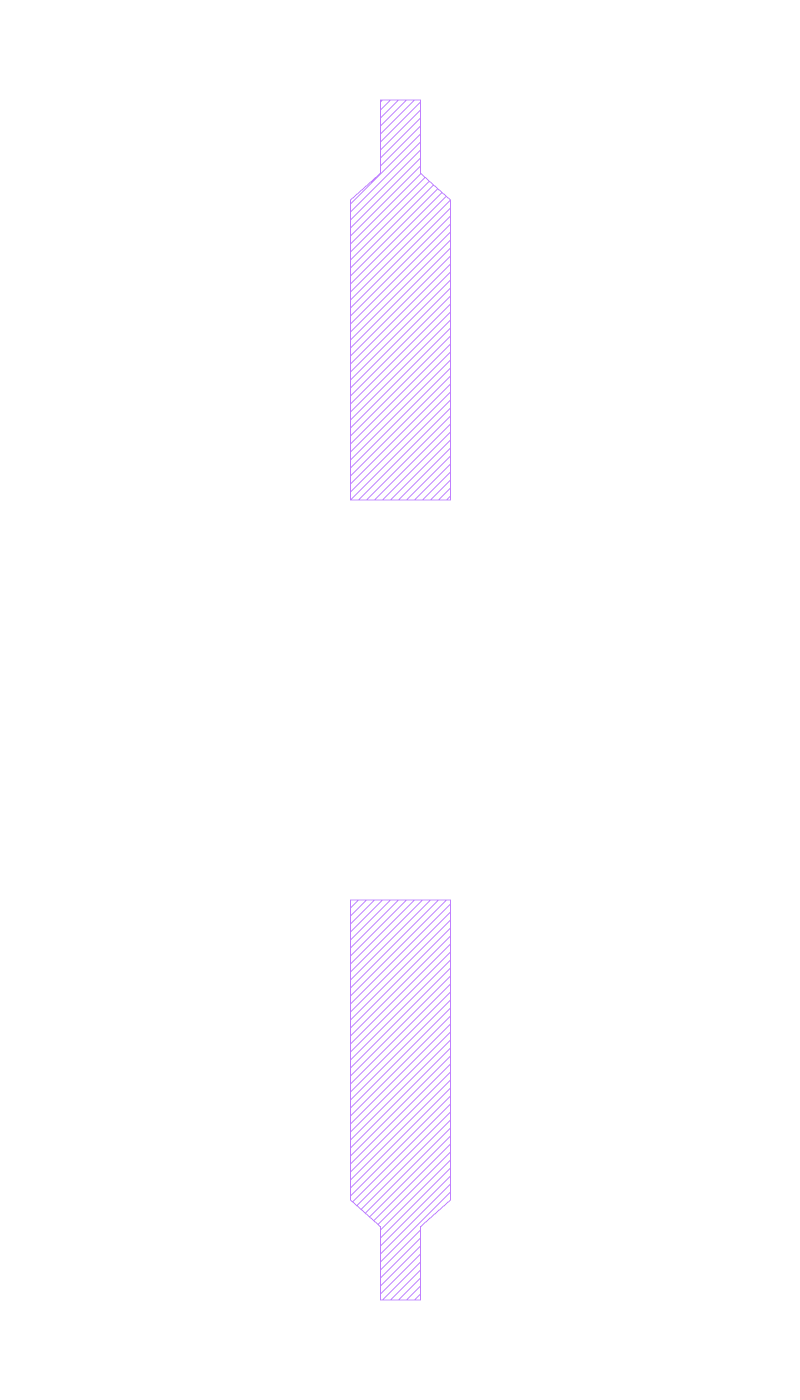

largest junction-layer XOR 0.0000 µm² (('top_finger', 'straight finger 2/0'))


| instance | layer | legacy (µm²) | rebuilt (µm²) | XOR (µm²) |
|---|---|---|---|---|
| top_finger | straight finger 2/0 | 6.960 | 6.960 | 0.0000 |

In [16]:
if L.legacy_available():
    ref = LB.legacy_chip(ID)
    cell = LB.legacy_path_cell("chip_10a_3X_SQUID.py", "create_squid", "top_finger", JS,
                               tmp="build/legacy_b/chip_10a_3x/main")
    print({c.name: c.dbbox().to_s() for c in cell[0].each_cell() if c.is_top()})   # the three top cells
    ref.cell_from("top_finger", *cell, 0, TOP_SHIFT)
    ref = L.shift_reference(ref, *SHIFT)
    from quantcore_circuits.live.snapshot import snapshot
    snapshot(ref.write(f"build/legacy_b/{ID}_legacy.oas"), OUT / f"{ID}_legacy.png",
             box=(x0 - 4, y0 - 7, x0 + 4, y0 + 7), size=(800, 1400))
    display(Image(filename=str(OUT / f"{ID}_legacy.png"), width=300))
    table, xor = LB.junction_xor(d, ref, names=["top_finger"])
    print(f"largest junction-layer XOR {max(xor.values()):.4f} µm² ({max(xor, key=xor.get)})")
    display(Markdown(table))
else:
    print("components/ (legacy library) not present: no legacy reference")

## 16 · Summary

- **Matches the source:** the two drawn `top_finger` fingers (XOR 0 µm² on the junction layer against the legacy
  `create_squid(2)` output); the completed SQUID (#24) follows the `squid_creator_HSQ` construction.
- **Differs, by the PDK:** centred in the die, shift **(0, −53) µm** (the SQUID now sits 53 µm below the die
  centre, the fingers 47 µm above it); the PDK die frame and device ID `CHIP10A 3X`; the PDK cheese band (fab cheese
  source "build", 38 holes around the cells).
- **Steps that do not apply:** pads, routes, LOM simulation (junction table instead), FEM.
- **Open:** 1 `pdk_rn` (168.8 kΩ); 0.39 µm fingers would give the PDK nominal SQUID (step 13).